# Chapter 18 · Hedging in practice: interactive demos

Companion to Chapter 18 of the [MFE 230D lecture notes](https://gennaroalberto.github.io/mfe230d-derivatives/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/mfe230d-derivatives/blob/main/code/notebooks/18-hedging.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

The default is the course's test case $S=K=100$, $T=1$, $r=1\%$, $y=2\%$, $\sigma=20\%$ (call price $7.36429$).
A dealer sells the call, rebalances a delta hedge at $m$ equally spaced dates, reinvests the dividends in the stock,
and we look at her hedging error $X_T-(S_T-K)^+$ in time-$T$ money. Path counts are kept small so that each figure
draws in a few seconds; the notes use more paths.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/mfe230d-derivatives#subdirectory=code"

import warnings
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from mfe230d import bs
from mfe230d import hedging as H
from mfe230d.style import COBALT, GOLD, GREY, INK, use_style

warnings.simplefilter("ignore")
use_style()
GREEN = "#1BAF7A"
S, T, r, y = 100.0, 1.0, 0.01, 0.02

## 1. Discrete delta hedging: the rate $m^{-1/2}$

Proposition 18.3: the mean squared error of the $m$-date hedge is $\frac{\sigma^4h}{2}I_\mu+o(h)$ with $h=T/m$, where
$I_\mu=\int_0^T\mathbb E[e^{-2rt}S_t^4\Gamma(t,S_t)^2]\,dt$ is computed under the real-world drift $\mu$. Left: the error
distribution for one $m$ (peaked, with heavy tails from the paths that end near the strike). Right: $\sqrt m$ times the
root-mean-square error against $m$, with the limit $e^{rT}\sigma^2\sqrt{TI_\mu/2}$ dashed. The drift is
the real-world total return; the hedge never uses it.

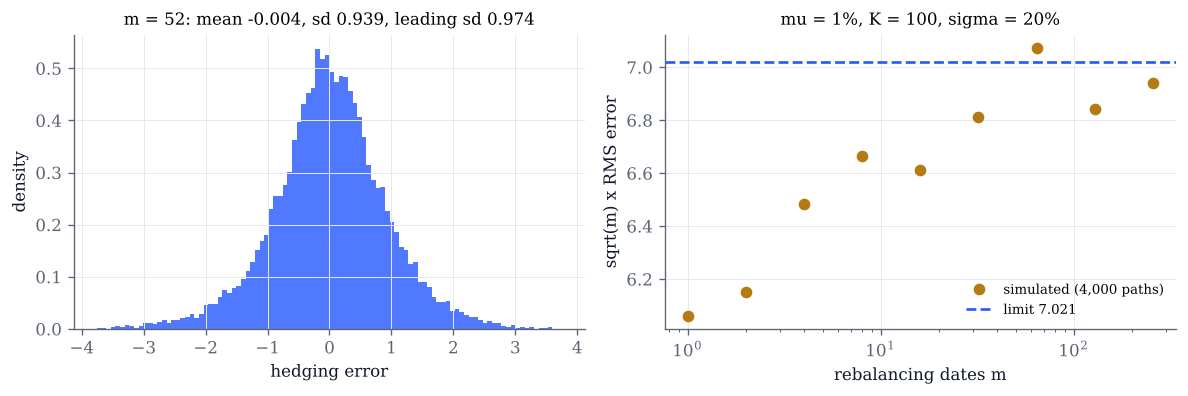

In [2]:
def discrete(m=52, mu=0.01, K=100.0, sigma=0.2, seed=18):
    P = dict(S=S, K=K, T=T, r=r, y=y, sigma=sigma)
    e = H.hedge_experiment(**P, m=m, n=20_000, mu=mu, seed=seed)["error"]
    s = H.summarize(e)
    ms = 2 ** np.arange(0, 9)
    rms = [H.summarize(H.hedge_stream(**P, m=int(k), n=4_000, mu=mu, seed=seed + int(k))["error"])["rms"] for k in ms]
    lim = H.asymptotic_sd(**P, m=1, mu=mu)
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.4))
    w = max(4 * s["sd"], 1e-3)
    ax.hist(e, bins=np.linspace(s["mean"] - w, s["mean"] + w, 101), density=True, color=COBALT, alpha=0.8)
    ax.set(xlabel="hedging error", ylabel="density",
           title=f"m = {m}: mean {s['mean']:.3f}, sd {s['sd']:.3f}, leading sd {lim / np.sqrt(m):.3f}")
    bx.semilogx(ms, np.sqrt(ms) * np.array(rms), "o", color=GOLD, label="simulated (4,000 paths)")
    bx.axhline(lim, color=COBALT, ls="--", label=f"limit {lim:.3f}")
    bx.set(xlabel="rebalancing dates m", ylabel="sqrt(m) x RMS error", title=f"mu = {mu:.0%}, K = {K:g}, sigma = {sigma:.0%}")
    bx.legend(fontsize=8); fig.tight_layout(); plt.show()

discrete()

In [3]:
# Explore: move the strike away from the money, or the drift away from r. What happens to the constant, and why?
interact(discrete,
         m=IntSlider(value=52, min=1, max=365, continuous_update=False, description="dates m"),
         mu=FloatSlider(value=0.01, min=-0.3, max=0.4, step=0.05, continuous_update=False, description="drift μ"),
         K=FloatSlider(value=100.0, min=60.0, max=150.0, step=5.0, continuous_update=False, description="strike K"),
         sigma=FloatSlider(value=0.2, min=0.05, max=0.6, step=0.05, continuous_update=False, description="σ"),
         seed=IntSlider(value=18, min=0, max=1000, continuous_update=False, description="seed"));

## 2. Hedging at the implied or at the realised volatility

Proposition 18.5: a call bought at the implied volatility $\sigma_i$ and hedged at $\sigma_h$ earns
$\frac12\int_0^Te^{-rt}\Gamma_hS_t^2(\sigma_r^2-\sigma_h^2)\,dt$ when the stock realises $\sigma_r$. Hedged at $\sigma_r$, the final P&L
is the locked-in $V_r-V_i$ (dotted), but its mark-to-market wanders; hedged at $\sigma_i$, the P&L grows smoothly and its
final value depends on the path, with the mean of Proposition 18.7 (dashed). Daily rebalancing adds the
discrete-hedging noise of section 1 to both.

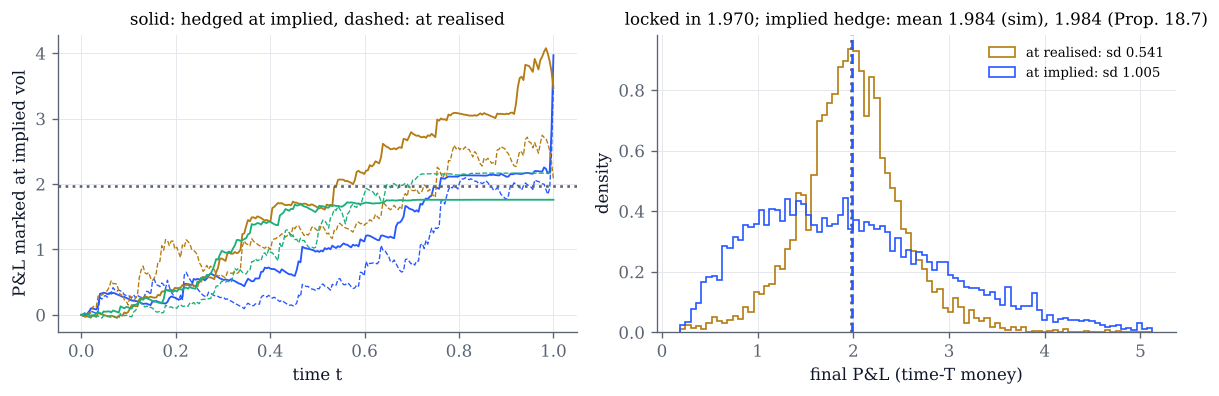

In [4]:
def implied(sigma_i=0.20, sigma_r=0.25, mu=0.10, m=252, seed=18):
    K = 100.0
    Vi, Vr = bs.call(S, K, T, r, y, sigma_i), bs.call(S, K, T, r, y, sigma_r)
    t, paths = H.simulate_stock(S, T, m, 5_000, mu, y, sigma_r, seed=seed)
    g = np.exp(r * T)
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.4))
    mi = g * H.mark_to_market(paths[:3], t, K, r, y, sigma_i, sigma_i, Vi)
    mr = g * H.mark_to_market(paths[:3], t, K, r, y, sigma_r, sigma_i, Vi)
    for j, col in enumerate((COBALT, GOLD, GREEN)):
        ax.plot(t, mi[j], color=col, lw=1.1)
        ax.plot(t, mr[j], color=col, lw=0.8, ls="--")
    ax.axhline(g * (Vr - Vi), color=GREY, ls=":")
    ax.set(xlabel="time t", ylabel="P&L marked at implied vol", title="solid: hedged at implied, dashed: at realised")
    pr = -H.hedge_paths(paths, t, K, r, y, sigma_r, premium=Vi)["error"]
    pi = -H.hedge_paths(paths, t, K, r, y, sigma_i, premium=Vi)["error"]
    lo, hi = np.quantile(np.concatenate([pr, pi]), [0.002, 0.998])
    bins = np.linspace(lo, hi, 91)
    bx.hist(pr, bins=bins, density=True, histtype="step", color=GOLD, label=f"at realised: sd {pr.std():.3f}")
    bx.hist(pi, bins=bins, density=True, histtype="step", color=COBALT, label=f"at implied: sd {pi.std():.3f}")
    bx.axvline(g * (Vr - Vi), color=GREY, ls=":")
    bx.axvline(g * H.expected_vol_pnl(S, K, T, r, y, sigma_i, sigma_r, mu), color=COBALT, ls="--")
    bx.set(xlabel="final P&L (time-T money)", ylabel="density",
           title=f"locked in {g * (Vr - Vi):.3f}; implied hedge: mean {pi.mean():.3f} (sim), "
                 f"{g * H.expected_vol_pnl(S, K, T, r, y, sigma_i, sigma_r, mu):.3f} (Prop. 18.7)")
    bx.legend(fontsize=8); fig.tight_layout(); plt.show()

implied()

In [5]:
# Explore: set sigma_r below sigma_i (the option was dear). Then push the drift far from r: which hedge is affected?
interact(implied,
         sigma_i=FloatSlider(value=0.20, min=0.05, max=0.6, step=0.01, continuous_update=False, description="σ implied"),
         sigma_r=FloatSlider(value=0.25, min=0.05, max=0.6, step=0.01, continuous_update=False, description="σ realised"),
         mu=FloatSlider(value=0.10, min=-0.3, max=0.4, step=0.05, continuous_update=False, description="drift μ"),
         m=IntSlider(value=252, min=12, max=1000, continuous_update=False, description="dates m"),
         seed=IntSlider(value=18, min=0, max=1000, continuous_update=False, description="seed"));

## 3. Transaction costs and Leland's volatility

A trade of $q$ shares at price $S$ costs $\frac k2|q|S$ ($k$ is the round-trip cost; the course's one-way cost is $k/2$).
Hedging at $\sigma$, the costs grow like $\sqrt m$. Leland's volatility (18.8),
$\hat\sigma^2=\sigma^2\big(1+\sqrt{2/\pi}\,k/(\sigma\sqrt h)\big)$, charges a premium that pays for them on average. Solid lines are
means, dashed lines standard deviations of the error, against the number of dates.

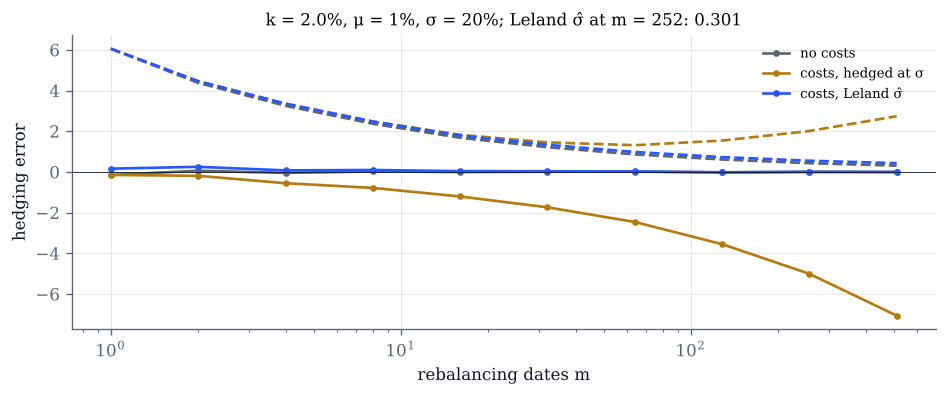

In [6]:
def leland(k=0.02, mu=0.01, sigma=0.2, seed=180):
    P = dict(S=S, K=100.0, T=T, r=r, y=y, sigma=sigma)
    ms = 2 ** np.arange(0, 10)
    fig, ax = plt.subplots(figsize=(8, 3.4))
    for lab, col, lel, kk in (("no costs", GREY, False, 0.0), ("costs, hedged at σ", GOLD, False, k),
                              ("costs, Leland σ̂", COBALT, True, k)):
        mean, sd = [], []
        for m in ms:
            sh = H.leland_vol(sigma, kk, T / m) if lel else sigma
            e = H.hedge_stream(**P, m=int(m), n=3_000, k=kk, mu=mu, sigma_hedge=sh, seed=seed + int(m))["error"]
            mean.append(e.mean()); sd.append(e.std())
        ax.semilogx(ms, mean, "o-", color=col, ms=3, label=lab)
        ax.semilogx(ms, sd, "--", color=col)
    ax.axhline(0, color=INK, lw=0.5)
    ax.set(xlabel="rebalancing dates m", ylabel="hedging error",
           title=f"k = {k:.1%}, μ = {mu:.0%}, σ = {sigma:.0%}; Leland σ̂ at m = 252: {H.leland_vol(sigma, k, T / 252):.3f}")
    ax.legend(fontsize=8); fig.tight_layout(); plt.show()

leland()

In [7]:
# Explore: raise k to 10% and watch the Leland mean drift below zero as m grows (Theorem 18.9(ii)).
interact(leland,
         k=FloatSlider(value=0.02, min=0.0, max=0.10, step=0.005, readout_format=".3f", continuous_update=False, description="cost k"),
         mu=FloatSlider(value=0.01, min=-0.3, max=0.4, step=0.05, continuous_update=False, description="drift μ"),
         sigma=FloatSlider(value=0.2, min=0.05, max=0.6, step=0.05, continuous_update=False, description="σ"),
         seed=IntSlider(value=180, min=0, max=1000, continuous_update=False, description="seed"));

## Things to try

- In section 1, move the strike to $60$ or $150$: the error almost vanishes. Which part of $I_\mu$ has disappeared?
- In section 1, take $m=1$ and then $m=4$: how far is the simulated standard deviation from the leading term
  $e^{rT}\sigma^2\sqrt{TI_\mu/2}/\sqrt m$ printed in the title?
- In section 2, set $\sigma_r=\sigma_i$: both hedges should replicate. What is left on the histograms, and where does it
  come from?
- In section 2, with $\sigma_r>\sigma_i$, find a drift for which the implied hedge earns less on average than the locked-in
  amount. Can it ever lose money in continuous time?
- In section 3, set $k=0$: the three curves should agree. Then compare the standard deviation of Leland's strategy
  with the one without costs: does Leland's adjustment remove the costs' randomness too?